# Historical experiment — archived, not a validated evaluation

This is an archival copy of the supplied notebook, including the original code and saved outputs. SHA-256 of the supplied notebook: `7f247778a37f2c1666b32513762cf36fb7874b47c7d4a295659f354eac0b0287`. All original cells and outputs follow unchanged.

**Do not execute this historical notebook in the project directory.** Several cells overwrite model files or export patient-derived expression files; some depend on missing or out-of-order state. Use `revised_evaluation.ipynb` for the revised workflow.

Preprocessing and feature selection were fitted before the test split, and SMOTE was applied before cross-validation. The shown metrics are not an unbiased evaluation. The saved artifacts have not been proven to originate from this notebook. “Biomarker,” “diagnosis,” and causal interpretations in historical cells or plots are not established by the experiment; feature importance is global model behavior. This is not clinical evidence or advice.


# BioVis-Cancer: Pipeline Deteksi Stadium Kanker Paru-Paru
**Dataset:** TCGA-LUAD (Lung Adenocarcinoma) RNA-Seq
**Tujuan:** Mengklasifikasikan stadium kanker (Stage I, II, III, IV) berbasis data ekspresi gen dan memvisualisasikan biomarker penyumbang utama.

In [ ]:
import requests
import json
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from imblearn.over_sampling import SMOTE
import joblib

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 7)

## 1. Akuisisi Data Kanker Paru-Paru & Metadata Klinis (GDC API)
Mengunduh data RNA-Seq khusus untuk `TCGA-LUAD` dan mengekstrak `tumor_stage` dari rekam medis pasien.

In [ ]:
GDC_API = 'https://api.gdc.cancer.gov/files'

params = {
    'filters': json.dumps({
        'op': 'and',
        'content': [
            {'op': '=', 'content': {'field': 'cases.project.project_id', 'value': 'TCGA-LUAD'}},
            {'op': '=', 'content': {'field': 'data_category', 'value': 'Transcriptome Profiling'}},
            {'op': '=', 'content': {'field': 'data_type', 'value': 'Gene Expression Quantification'}},
            {'op': '=', 'content': {'field': 'experimental_strategy', 'value': 'RNA-Seq'}},
            {'op': '=', 'content': {'field': 'analysis.workflow_type', 'value': 'STAR - Counts'}},
            {'op': '=', 'content': {'field': 'access', 'value': 'open'}},
        ]
    }),
    # PERBAIKAN: Memanggil ajcc_pathologic_stage dari rekam medis pasien
    'fields': 'file_id,cases.diagnoses.ajcc_pathologic_stage,cases.diagnoses.tumor_stage',
    'format': 'JSON',
    'size': '2000'
}

print('Querying GDC API untuk data Paru-Paru (LUAD)...')
response = requests.get(GDC_API, params=params)
data = response.json()
files = data['data']['hits']
print(f'Ditemukan {len(files)} metadata file RNA-Seq TCGA-LUAD')

GDC_DATA_API = 'https://api.gdc.cancer.gov/data/'

limit_files = 400
files_to_download = files[:limit_files]

data_dict = {}
target_dict = {}

print(f"Mengunduh dan memproses {limit_files} file...")

for i, f in enumerate(files_to_download):
    file_id = f['file_id']
    try:
        diagnoses = f['cases'][0]['diagnoses'][0]

        # PERBAIKAN: Mengambil data dari ajcc_pathologic_stage. Jika kosong, cari di tumor_stage.
        stage_raw = diagnoses.get('ajcc_pathologic_stage', diagnoses.get('tumor_stage', 'not reported'))

        if stage_raw is None:
            stage_raw = 'not reported'

        stage_raw = stage_raw.lower()

        # Pengelompokan logis Stadium ke dalam 4 Kelas (0, 1, 2, 3)
        # Urutan ini (IV -> III -> II -> I) sangat penting agar 'stage iiia' tidak salah terbaca sebagai 'stage ii'
        if 'stage iv' in stage_raw:
            label = 3
        elif 'stage iii' in stage_raw:
            label = 2
        elif 'stage ii' in stage_raw:
            label = 1
        elif 'stage i' in stage_raw:
            label = 0
        else:
            continue # Abaikan pasien jika data stadiumnya tidak ada

        # Eksekusi unduhan RNA-Seq hanya jika label stadium berhasil didapatkan
        res = requests.get(GDC_DATA_API + file_id)
        df_temp = pd.read_csv(io.StringIO(res.text), sep='\t', skiprows=1)
        df_temp = df_temp[df_temp['gene_id'].str.startswith('ENSG', na=False)]
        df_temp.set_index('gene_id', inplace=True)

        data_dict[file_id] = df_temp['fpkm_unstranded']
        target_dict[file_id] = label

    except Exception as e:
        continue

    if (i+1) % 50 == 0:
        print(f"[{i+1}/{limit_files}] file diproses.")

df_raw = pd.DataFrame(data_dict)
print(f"Penggabungan selesai. Ukuran matriks: {df_raw.shape[0]} gen x {df_raw.shape[1]} pasien")

Querying GDC API untuk data Paru-Paru (LUAD)...
Ditemukan 601 metadata file RNA-Seq TCGA-LUAD
Mengunduh dan memproses 400 file...
[50/400] file diproses.
[100/400] file diproses.
[150/400] file diproses.
[200/400] file diproses.
[250/400] file diproses.
[300/400] file diproses.
[350/400] file diproses.
[400/400] file diproses.
Penggabungan selesai. Ukuran matriks: 60660 gen x 394 pasien


## 2. Preprocessing & Ekstraksi Biomarker
Melakukan normalisasi dengan QuantileTransformer dan menyeleksi 50 gen (biomarker) yang paling diskriminatif dalam membedakan stadium kanker paru-paru menggunakan uji statistik ANOVA.

In [ ]:
X = df_raw.T
y_series = X.index.map(target_dict)

valid_indices = y_series.notna()
X = X[valid_indices]
y = y_series[valid_indices].astype(int).values
X = X.fillna(0)

# Transformasi Data
X_log = np.log1p(X)
scaler = QuantileTransformer(output_distribution='normal', random_state=42)
X_scaled = scaler.fit_transform(X_log)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

# FEATURE SELECTION (Mencari Biomarker Terbaik)
# Memilih 50 gen paling signifikan secara statistik untuk membedakan stadium
selector = SelectKBest(f_classif, k=200)
X_selected = selector.fit_transform(X_scaled_df, y)

# Mengambil nama-nama gen (Biomarker) yang terpilih
selected_gene_ids = X.columns[selector.get_support()]
X_selected_df = pd.DataFrame(X_selected, columns=selected_gene_ids, index=X.index)

print(f"Selesai! Fitur telah direduksi menjadi {X_selected_df.shape[1]} biomarker utama.")

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_data.py:2829: UserWarning: n_quantiles (1000) is greater than the total number of samples (394). n_quantiles is set to n_samples.
  warnings.warn(


Selesai! Fitur telah direduksi menjadi 200 biomarker utama.


/tmp/ipykernel_5546/3582156180.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_mapped, order=stage_names, palette="viridis", ax=axes[0])
/tmp/ipykernel_5546/3582156180.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=y_mapped, y=X_selected_df[top_gene_id], order=stage_names, palette="viridis", ax=axes[2])


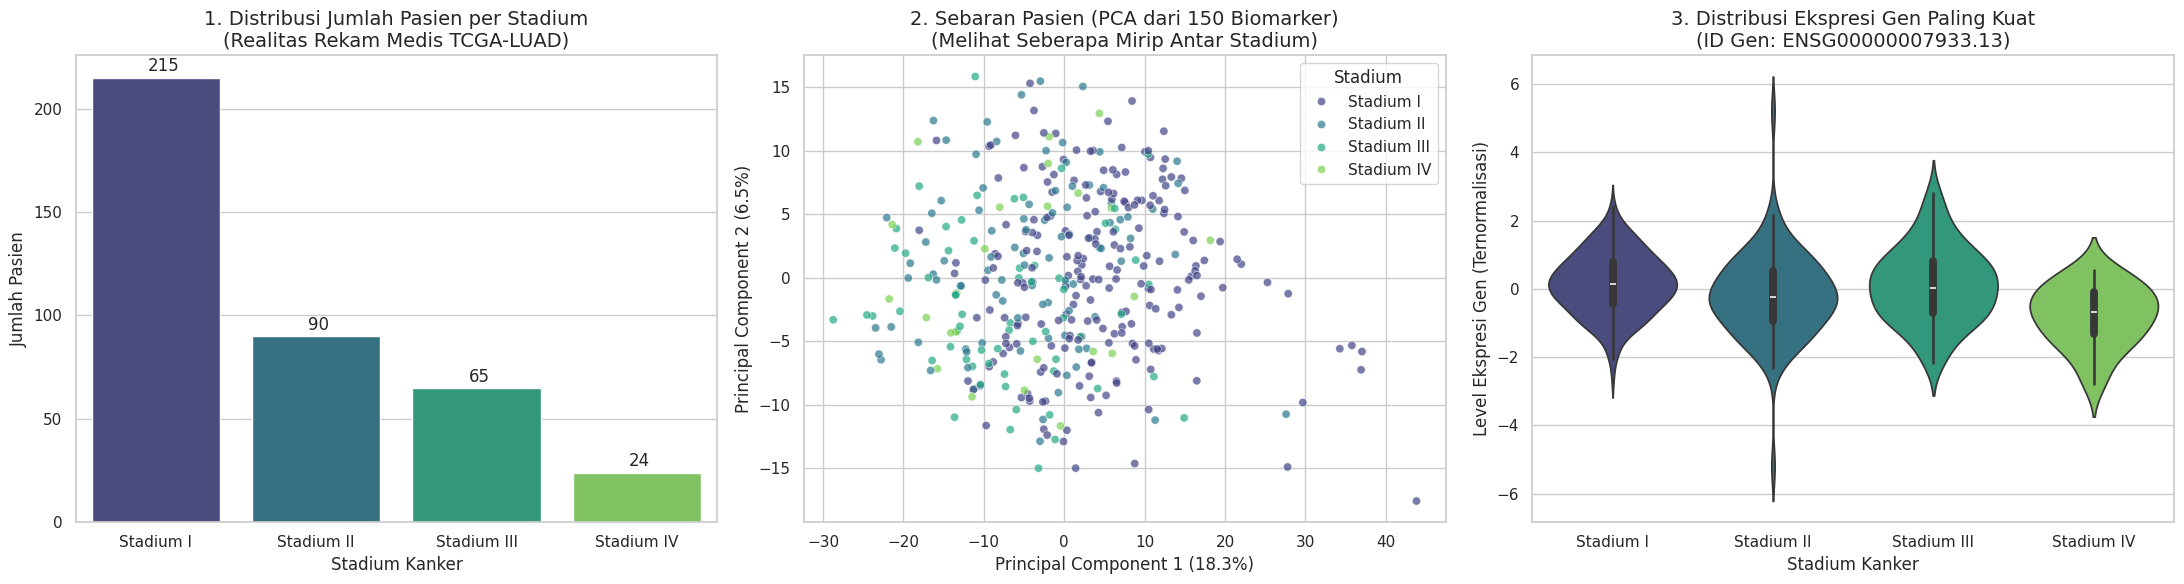

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# Setup visualisasi
sns.set_theme(style="whitegrid")
stage_names = ["Stadium I", "Stadium II", "Stadium III", "Stadium IV"]
y_mapped = [stage_names[label] for label in y]

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# ==========================================
# 1. PLOT DISTRIBUSI KELAS (Imbalance Check)
# ==========================================
sns.countplot(x=y_mapped, order=stage_names, palette="viridis", ax=axes[0])
axes[0].set_title('1. Distribusi Jumlah Pasien per Stadium\n(Realitas Rekam Medis TCGA-LUAD)', fontsize=14)
axes[0].set_xlabel('Stadium Kanker')
axes[0].set_ylabel('Jumlah Pasien')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + 0.35, p.get_height() + 3))

# ==========================================
# 2. PLOT PCA 2D (Visualisasi Tumpang Tindih Biologis)
# ==========================================
# Mereduksi 150 gen biomarker menjadi 2 dimensi hanya untuk visualisasi
pca_eda = PCA(n_components=2, random_state=42)
X_pca_eda = pca_eda.fit_transform(X_selected_df)

sns.scatterplot(x=X_pca_eda[:, 0], y=X_pca_eda[:, 1], hue=y_mapped, hue_order=stage_names,
                palette="viridis", alpha=0.7, ax=axes[1])
axes[1].set_title('2. Sebaran Pasien (PCA dari 150 Biomarker)\n(Melihat Seberapa Mirip Antar Stadium)', fontsize=14)
axes[1].set_xlabel(f'Principal Component 1 ({pca_eda.explained_variance_ratio_[0]*100:.1f}%)')
axes[1].set_ylabel(f'Principal Component 2 ({pca_eda.explained_variance_ratio_[1]*100:.1f}%)')
axes[1].legend(title='Stadium')

# ==========================================
# 3. PLOT DISTRIBUSI GEN TERBAIK (Violin Plot)
# ==========================================
# Mengambil gen urutan pertama (paling signifikan dari ANOVA)
top_gene_id = selected_gene_ids[0]
sns.violinplot(x=y_mapped, y=X_selected_df[top_gene_id], order=stage_names, palette="viridis", ax=axes[2])
axes[2].set_title(f'3. Distribusi Ekspresi Gen Paling Kuat\n(ID Gen: {top_gene_id})', fontsize=14)
axes[2].set_xlabel('Stadium Kanker')
axes[2].set_ylabel('Level Ekspresi Gen (Ternormalisasi)')

plt.tight_layout()
plt.show()

## 3. Pelatihan Model Multi-Kelas
Mengatasi ketidakseimbangan jumlah pasien antar stadium menggunakan SMOTE, lalu melatih model Random Forest.

In [ ]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
import joblib

# 1. Stratifikasi pembagian data
X_train, X_test, y_train, y_test = train_test_split(X_selected_df, y, test_size=0.2, random_state=42, stratify=y)

# 2. SMOTE Klasik (Terbukti paling stabil untuk dataset genomik yang tumpang tindih)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# 3. Membangun Arsitektur Stacking (Dewan Pakar)
# 3 Dokter Spesialis: Random Forest, XGBoost, dan SVM
estimators = [
    ('rf', RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42)),
    ('xgb', xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.05, objective='multi:softprob', random_state=42)),
    ('svm', SVC(kernel='rbf', probability=True, random_state=42))
]

# Dokter Kepala: Logistic Regression
meta_model = LogisticRegression(max_iter=1000, random_state=42)

# Menggabungkan semuanya
stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=meta_model,
    cv=5
)

print("Melatih Model Final: Stacking Classifier (RF + XGBoost + SVM)...")
print("Proses ini membutuhkan waktu komputasi, silakan tunggu sebentar...")
stacking_clf.fit(X_train_smote, y_train_smote)

# 4. Prediksi & Evaluasi Final
y_pred = stacking_clf.predict(X_test)
stage_names = ["Stadium I", "Stadium II", "Stadium III", "Stadium IV"]

print("\nClassification Report Final (Stacking Classifier):")
print(classification_report(y_test, y_pred, target_names=stage_names))

# 5. EKSPOR KOMPONEN UNTUK WEBSITE STREAMLIT
print("\nMenyimpan model ke dalam file .pkl...")
joblib.dump(scaler, 'scaler_luad.pkl')
joblib.dump(selector, 'biomarker_selector_luad.pkl')
joblib.dump(stacking_clf, 'model_stadium_luad.pkl')

print("Selesai! Komponen siap digunakan untuk menjalankan app.py")

Melatih Model Final: Stacking Classifier (RF + XGBoost + SVM)...
Proses ini membutuhkan waktu komputasi, silakan tunggu sebentar...

Classification Report Final (Stacking Classifier):
              precision    recall  f1-score   support

   Stadium I       0.60      0.95      0.74        43
  Stadium II       0.50      0.11      0.18        18
 Stadium III       1.00      0.31      0.47        13
  Stadium IV       0.67      0.40      0.50         5

    accuracy                           0.62        79
   macro avg       0.69      0.44      0.47        79
weighted avg       0.65      0.62      0.55        79


Menyimpan model ke dalam file .pkl...
Selesai! Komponen siap digunakan untuk menjalankan app.py


## 4. Visualisasi Evaluasi Klasifikasi (Confusion Matrix)

In [ ]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='OrRd',
            xticklabels=stage_names, yticklabels=stage_names)
plt.title('Confusion Matrix - Prediksi Stadium Kanker Paru-Paru')
plt.ylabel('Stadium Aktual (Rekam Medis)')
plt.xlabel('Stadium Prediksi (Model Komputasional)')
plt.show()

## 5. Visualisasi Biomarker Kanker Paru-Paru
Menampilkan tingkat kepentingan (feature importance) dari biomarker dan peta panas (heatmap) ekspresi gen berdasarkan tingkat keparahan stadium.

In [ ]:
# 1. Plot Feature Importance (10 Gen Teratas)
importances = rf_classifier.feature_importances_
indices = np.argsort(importances)[::-1][:10]
top_genes = selected_gene_ids[indices]
top_importances = importances[indices]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(x=top_importances, y=top_genes, palette="mako", ax=axes[0])
axes[0].set_title('Top 10 Biomarker Gen Paling Berpengaruh')
axes[0].set_xlabel('Tingkat Kepentingan (Random Forest Feature Importance)')
axes[0].set_ylabel('ID Gen (ENSG)')

# 2. Heatmap Ekspresi 10 Gen Biomarker antar Stadium
# Mengambil nilai rata-rata ekspresi dari 10 gen teratas per stadium
X_heatmap = X_selected_df[top_genes].copy()
X_heatmap['Stadium'] = y
mean_expression_per_stage = X_heatmap.groupby('Stadium').mean()
mean_expression_per_stage.index = stage_names

sns.heatmap(mean_expression_per_stage.T, cmap='coolwarm', annot=True, fmt=".2f", ax=axes[1])
axes[1].set_title('Pola Ekspresi Biomarker Berdasarkan Stadium')
axes[1].set_xlabel('Stadium Kanker Paru-Paru')
axes[1].set_ylabel('ID Gen Biomarker')

plt.tight_layout()
plt.show()

In [ ]:
# Menyimpan model (Gunakan sel ini jika ingin mengintegrasikannya ke web)
joblib.dump(scaler, 'scaler_luad.pkl')
joblib.dump(selector, 'biomarker_selector_luad.pkl')
joblib.dump(rf_classifier, 'model_stadium_luad.pkl')

print("Proses ekspor model Kanker Paru-Paru selesai.")

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# TAHAP 1: Filter Method (Cepat)
# Membuang puluhan ribu gen sampah, menyisakan 500 gen potensial
selector_anova = SelectKBest(f_classif, k=500)
X_anova = selector_anova.fit_transform(X_scaled_df, y)
anova_gene_ids = X_scaled_df.columns[selector_anova.get_support()]
X_anova_df = pd.DataFrame(X_anova, columns=anova_gene_ids, index=X_scaled_df.index)

print("Fase 1 Selesai: 500 gen potensial disaring menggunakan uji statistik.")

# TAHAP 2: Wrapper Method (Cerdas & Iteratif)
# Mesin akan melatih model berulang kali sambil membuang gen yang tidak bisa bekerja sama
# Menggunakan pemotongan per 10% (step=0.1) agar waktu komputasi tidak terlalu lama
rfe_estimator = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
selector_rfe = RFE(estimator=rfe_estimator, n_features_to_select=150, step=0.1)

print("Fase 2 Dimulai: RFE sedang mengeliminasi gen dan mencari 150 biomarker elit...")
print("Proses ini akan memakan waktu sekitar 1-3 menit, silakan bersabar.")

X_selected = selector_rfe.fit_transform(X_anova_df, y)
selected_gene_ids = anova_gene_ids[selector_rfe.get_support()]
X_selected_df = pd.DataFrame(X_selected, columns=selected_gene_ids, index=X_anova_df.index)

print(f"\nSelesai! Matriks data Anda kini direduksi menjadi {X_selected_df.shape[1]} biomarker paling esensial.")

Fase 1 Selesai: 500 gen potensial disaring menggunakan uji statistik.
Fase 2 Dimulai: RFE sedang mengeliminasi gen dan mencari 150 biomarker elit...
Proses ini akan memakan waktu sekitar 1-3 menit, silakan bersabar.

Selesai! Matriks data Anda kini direduksi menjadi 150 biomarker paling esensial.


In [ ]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report
import xgboost as xgb
import joblib

# 1. Stratifikasi & Penyeimbangan
X_train, X_test, y_train, y_test = train_test_split(X_selected_df, y, test_size=0.2, random_state=42, stratify=y)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# 2. Inisialisasi Model Dasar
xgb_base = xgb.XGBClassifier(objective='multi:softmax', num_class=4, random_state=42, eval_metric='mlogloss')

# 3. Mendefinisikan Ruang Pencarian Hyperparameter (Grid)
param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'gamma': [0, 0.1, 0.5, 1.0]
}

# 4. Melakukan Pencarian Kombinasi Terbaik (20 iterasi acak)
random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=20,                    # Mencoba 20 kombinasi pengaturan secara acak
    scoring='f1_macro',           # Fokus pada pemerataan F1-Score di seluruh kelas
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

print("Memulai Hyperparameter Tuning... (Ini akan melatih puluhan model, mohon tunggu)")
random_search.fit(X_train_smote, y_train_smote)

print(f"\n[BINGO!] Kombinasi Parameter Terbaik: {random_search.best_params_}")

# 5. Evaluasi Menggunakan "Mesin Emas" (Model Terbaik)
best_xgb = random_search.best_estimator_
y_pred = best_xgb.predict(X_test)
stage_names = ["Stadium I", "Stadium II", "Stadium III", "Stadium IV"]

print("\nClassification Report Final (RFE + Tuned XGBoost):")
print(classification_report(y_test, y_pred, target_names=stage_names))

# 6. EKSPOR KOMPONEN
print("\nMenyimpan seluruh komponen ke dalam .pkl...")
joblib.dump(scaler, 'scaler_luad.pkl')
joblib.dump(selector_anova, 'selector_anova_luad.pkl') # Menyimpan tahap 1
joblib.dump(selector_rfe, 'selector_rfe_luad.pkl')     # Menyimpan tahap 2
joblib.dump(best_xgb, 'model_stadium_luad.pkl')

print("Selesai! Komponen siap tempur.")

Memulai Hyperparameter Tuning... (Ini akan melatih puluhan model, mohon tunggu)
Fitting 3 folds for each of 20 candidates, totalling 60 fits

[BINGO!] Kombinasi Parameter Terbaik: {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.2, 'gamma': 0}

Classification Report Final (RFE + Tuned XGBoost):
              precision    recall  f1-score   support

   Stadium I       0.70      0.88      0.78        43
  Stadium II       0.40      0.22      0.29        18
 Stadium III       0.54      0.54      0.54        13
  Stadium IV       0.50      0.20      0.29         5

    accuracy                           0.63        79
   macro avg       0.54      0.46      0.47        79
weighted avg       0.59      0.63      0.60        79


Menyimpan seluruh komponen ke dalam .pkl...
Selesai! Komponen siap tempur.


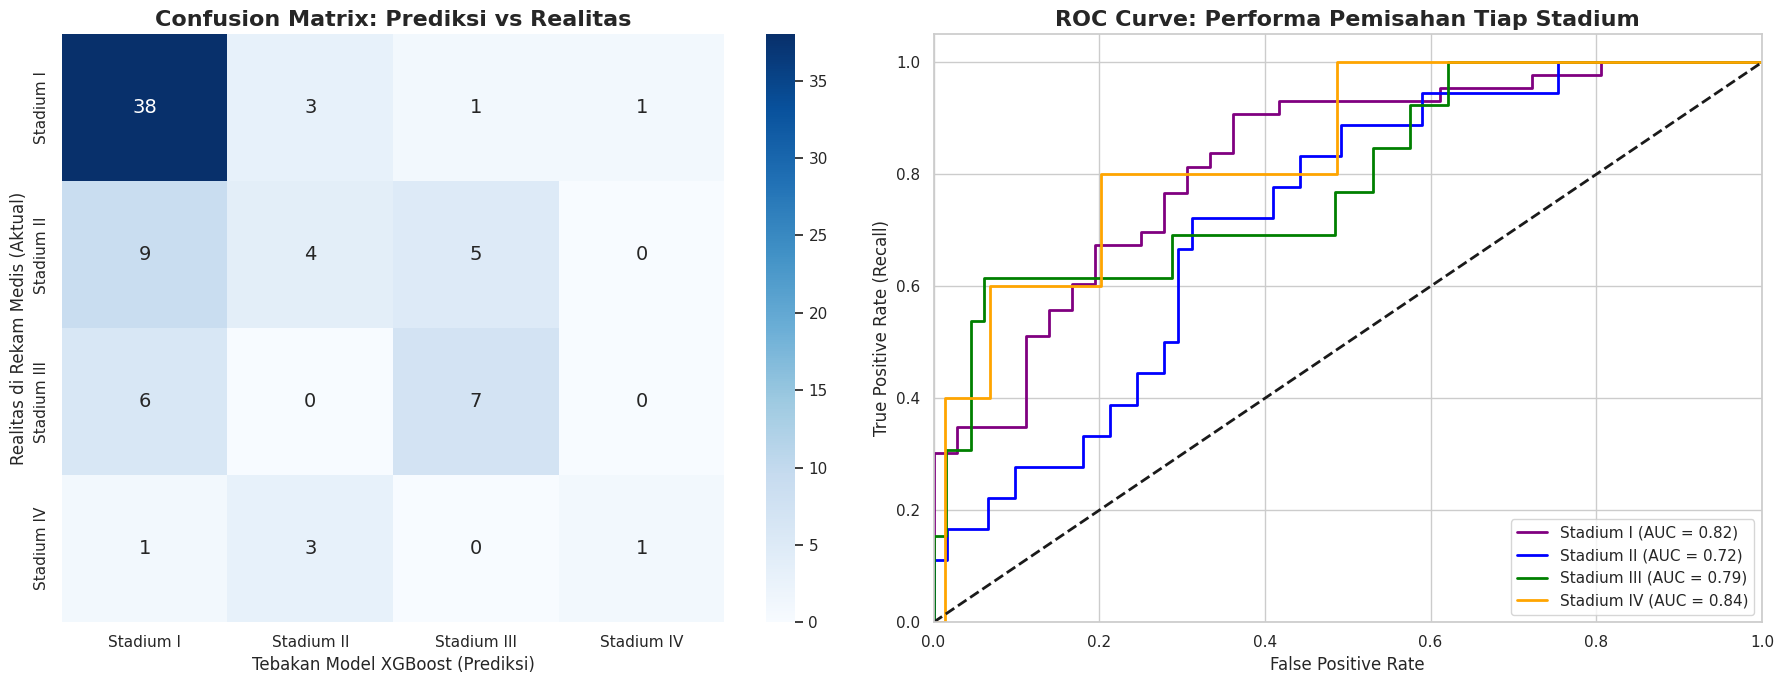

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
stage_names = ["Stadium I", "Stadium II", "Stadium III", "Stadium IV"]

# ==========================================
# 1. CONFUSION MATRIX (Peta Kebingungan Mesin)
# ==========================================
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=stage_names, yticklabels=stage_names,
            annot_kws={"size": 14})
axes[0].set_title('Confusion Matrix: Prediksi vs Realitas', fontsize=16, fontweight='bold')
axes[0].set_ylabel('Realitas di Rekam Medis (Aktual)', fontsize=12)
axes[0].set_xlabel('Tebakan Model XGBoost (Prediksi)', fontsize=12)

# ==========================================
# 2. MULTI-CLASS ROC CURVE (Kemampuan Pemisahan)
# ==========================================
# Binarize label untuk ROC Multi-kelas
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])
n_classes = y_test_bin.shape[1]
y_prob = best_xgb.predict_proba(X_test)

colors = ['purple', 'blue', 'green', 'orange']
for i, color in zip(range(n_classes), colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    axes[1].plot(fpr, tpr, color=color, lw=2,
                 label=f'{stage_names[i]} (AUC = {roc_auc:.2f})')

axes[1].plot([0, 1], [0, 1], 'k--', lw=2)
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate', fontsize=12)
axes[1].set_ylabel('True Positive Rate (Recall)', fontsize=12)
axes[1].set_title('ROC Curve: Performa Pemisahan Tiap Stadium', fontsize=16, fontweight='bold')
axes[1].legend(loc="lower right", fontsize=11)

plt.tight_layout()
plt.show()

/tmp/ipykernel_5546/2982000727.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_importances, y=top_genes, palette="magma", ax=axes[0])


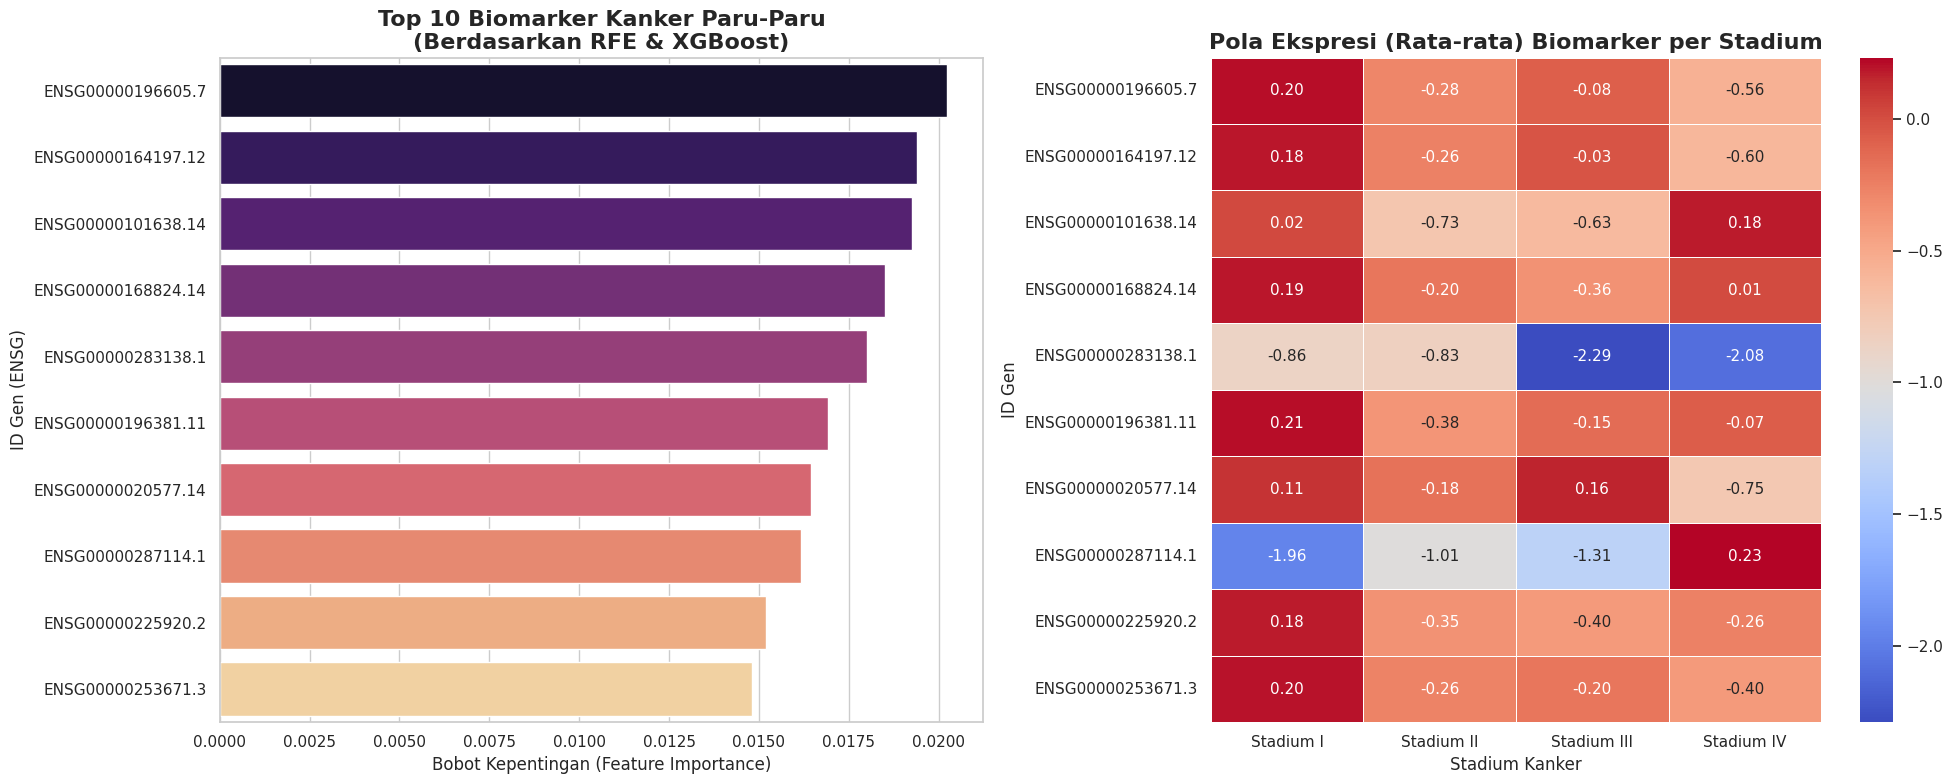

In [ ]:
# ==========================================
# 3. FEATURE IMPORTANCE (10 Biomarker Terbaik)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Mengambil tingkat kepentingan gen dari XGBoost
importances = best_xgb.feature_importances_
# Mengurutkan dari yang paling penting
indices = np.argsort(importances)[::-1][:10]
top_genes = selected_gene_ids[indices]
top_importances = importances[indices]

sns.barplot(x=top_importances, y=top_genes, palette="magma", ax=axes[0])
axes[0].set_title('Top 10 Biomarker Kanker Paru-Paru\n(Berdasarkan RFE & XGBoost)', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Bobot Kepentingan (Feature Importance)', fontsize=12)
axes[0].set_ylabel('ID Gen (ENSG)', fontsize=12)

# ==========================================
# 4. HEATMAP EKSPRESI BIOMARKER (Pola Perubahan)
# ==========================================
# Mengambil nilai rata-rata ekspresi 10 gen top ini di tiap stadium
df_heatmap = X_selected_df[top_genes].copy()
df_heatmap['Stadium'] = y
mean_expression = df_heatmap.groupby('Stadium').mean()
mean_expression.index = stage_names

# Visualisasi peta panas
sns.heatmap(mean_expression.T, cmap='coolwarm', annot=True, fmt=".2f",
            linewidths=.5, ax=axes[1], annot_kws={"size": 11})
axes[1].set_title('Pola Ekspresi (Rata-rata) Biomarker per Stadium', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Stadium Kanker', fontsize=12)
axes[1].set_ylabel('ID Gen', fontsize=12)

plt.tight_layout()
plt.show()

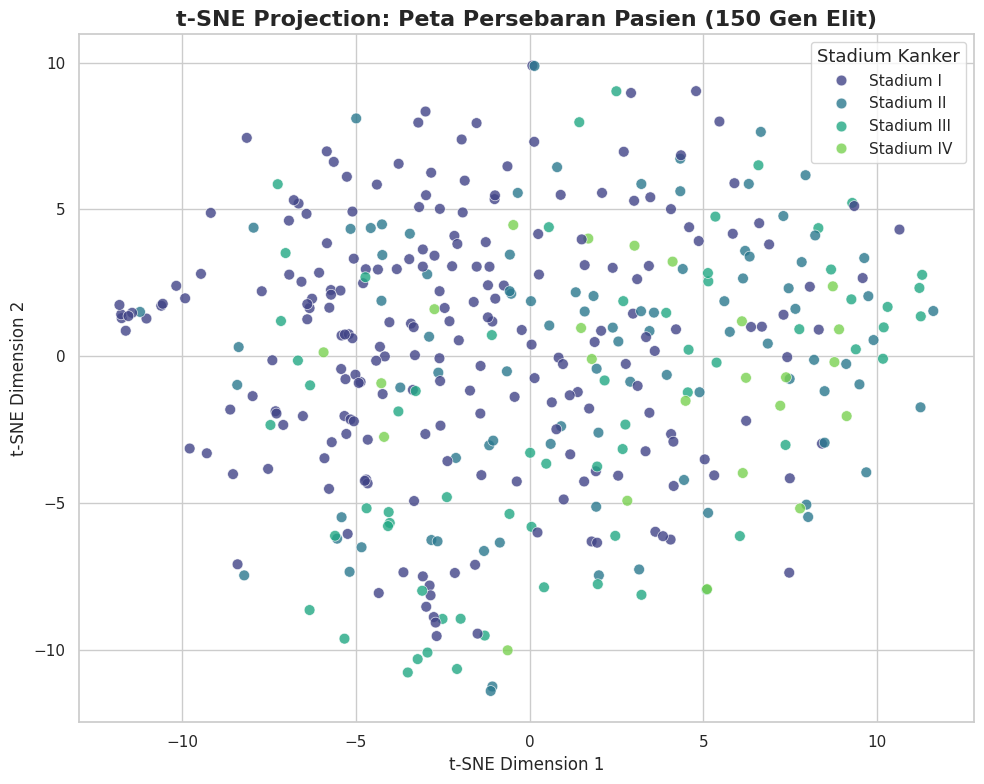

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# Menjalankan algoritma t-SNE pada 150 Gen Elit hasil RFE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_selected_df)

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1],
    hue=[stage_names[label] for label in y],
    hue_order=stage_names,
    palette="viridis",
    alpha=0.8,
    s=60,
    edgecolor='w',
    linewidth=0.5
)

plt.title('t-SNE Projection: Peta Persebaran Pasien (150 Gen Elit)', fontsize=16, fontweight='bold')
plt.xlabel('t-SNE Dimension 1', fontsize=12)
plt.ylabel('t-SNE Dimension 2', fontsize=12)
plt.legend(title='Stadium Kanker', title_fontsize='13', fontsize='11', loc='best')
plt.tight_layout()
plt.show()

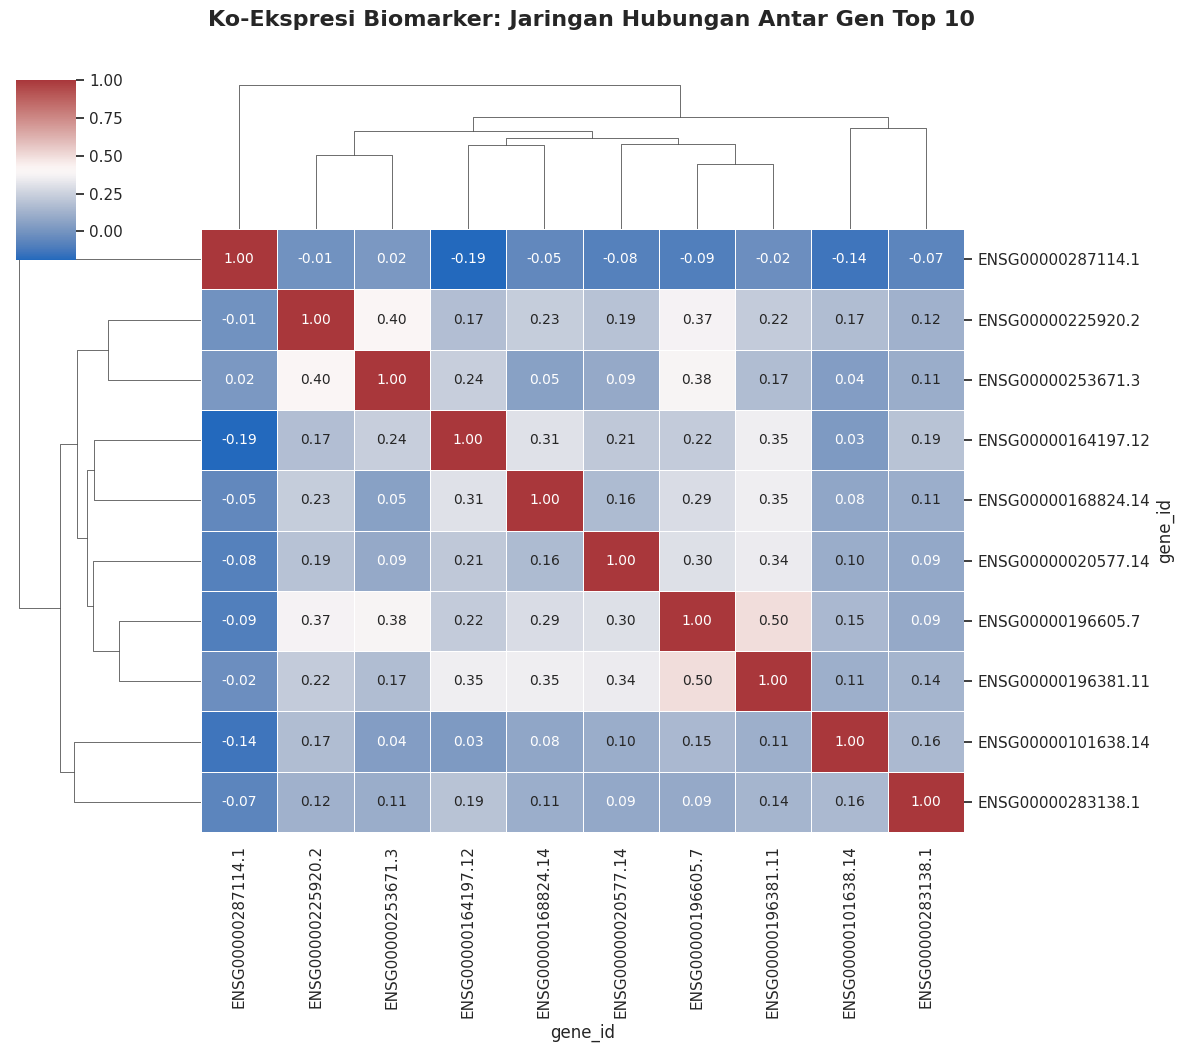

In [ ]:
# Mengambil 10 gen terbaik (variabel top_genes sudah ada dari sel sebelumnya)
top_genes_data = X_selected_df[top_genes]

# Menghitung korelasi (hubungan) antar 10 gen tersebut
gene_correlation = top_genes_data.corr()

# Membuat Clustermap
g = sns.clustermap(
    gene_correlation,
    cmap="vlag",
    annot=True,
    fmt=".2f",
    figsize=(12, 10),
    annot_kws={"size": 10},
    linewidths=.5,
    cbar_pos=(0.02, 0.8, 0.05, 0.18)
)

g.fig.suptitle('Ko-Ekspresi Biomarker: Jaringan Hubungan Antar Gen Top 10',
               y=1.05, fontsize=16, fontweight='bold')
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# 1. Mengambil data pasien indeks ke-10 (Anda bebas mengganti angka 10 dengan 0, 5, atau 20)
pasien_scaled = X_scaled_df.iloc[[10]]

# 2. MENGEMBALIKAN KE BENTUK ASLI (Reverse Engineering)
# Mundur dari Scaler
pasien_log = scaler.inverse_transform(pasien_scaled)
# Mundur dari Log1p menggunakan expm1
pasien_raw = np.expm1(pasien_log)

# 3. Membentuk format kolom yang persis seperti format asli portal GDC
df_dummy = pd.DataFrame({
    'gene_id': X_scaled_df.columns,
    'fpkm_unstranded': pasien_raw[0]
})

# 4. Menambahkan satu baris metadata palsu di atas (karena app.py memiliki skiprows=1)
df_dummy.loc[-1] = ['N_unmapped', 0]
df_dummy.index = df_dummy.index + 1
df_dummy.sort_index(inplace=True)

# 5. Simpan menjadi file TSV
df_dummy.to_csv('pasien_dummy_test.tsv', sep='\t', index=False)
print("Berhasil! File 'pasien_dummy_test.tsv' sudah dibuat dan siap diunggah ke website Anda.")

Berhasil! File 'pasien_dummy_test.tsv' sudah dibuat dan siap diunggah ke website Anda.


In [ ]:
import pandas as pd
import numpy as np

# Mengubah label y menjadi array agar mudah dicari
y_array = np.array(y)

# Mencari indeks pasien pertama untuk masing-masing stadium
stadium_indices = {
    "Stadium_I": np.where(y_array == 0)[0][0],   # Pasien berlabel 0
    "Stadium_II": np.where(y_array == 1)[0][0],  # Pasien berlabel 1
    "Stadium_III": np.where(y_array == 2)[0][0], # Pasien berlabel 2
    "Stadium_IV": np.where(y_array == 3)[0][0]   # Pasien berlabel 3
}

for nama_stadium, idx in stadium_indices.items():
    # 1. Ambil data pasien tersebut
    pasien_scaled = X_scaled_df.iloc[[idx]]

    # 2. Kembalikan ke format biologis asli (Reverse Engineering)
    pasien_log = scaler.inverse_transform(pasien_scaled)
    pasien_raw = np.expm1(pasien_log)

    # 3. Bentuk tabel format GDC
    df_dummy = pd.DataFrame({
        'gene_id': X_scaled_df.columns,
        'fpkm_unstranded': pasien_raw[0]
    })

    # 4. Simpan menjadi file TSV
    nama_file = f'pasien_{nama_stadium}_test.tsv'
    df_dummy.to_csv(nama_file, sep='\t', index=False)
    print(f"✅ File {nama_file} berhasil dibuat! (Diambil dari pasien indeks ke-{idx})")

print("\nSelesai! Anda sekarang memiliki 4 file TSV untuk keperluan demo.")

✅ File pasien_Stadium_I_test.tsv berhasil dibuat! (Diambil dari pasien indeks ke-0)
✅ File pasien_Stadium_II_test.tsv berhasil dibuat! (Diambil dari pasien indeks ke-2)
✅ File pasien_Stadium_III_test.tsv berhasil dibuat! (Diambil dari pasien indeks ke-5)
✅ File pasien_Stadium_IV_test.tsv berhasil dibuat! (Diambil dari pasien indeks ke-3)

Selesai! Anda sekarang memiliki 4 file TSV untuk keperluan demo.


In [ ]:
import pandas as pd
import numpy as np

# Mengubah label y menjadi array
y_array = np.array(y)

# Mencari SEMUA indeks pasien yang berlabel 3 (Stadium IV)
semua_idx_stadium_4 = np.where(y_array == 3)[0]

print(f"Total pasien Stadium IV di dataset: {len(semua_idx_stadium_4)} orang")

# Kita ambil pasien urutan ke-2 (indeks [1]) dan urutan ke-3 (indeks [2]) dari daftar tersebut
indeks_pilihan = [semua_idx_stadium_4[1], semua_idx_stadium_4[2]]

for urutan, idx in enumerate(indeks_pilihan, start=2):
    # 1. Ambil data pasien
    pasien_scaled = X_scaled_df.iloc[[idx]]

    # 2. Reverse Engineering ke nilai FPKM asli
    pasien_log = scaler.inverse_transform(pasien_scaled)
    pasien_raw = np.expm1(pasien_log)

    # 3. Bentuk tabel format GDC
    df_dummy = pd.DataFrame({
        'gene_id': X_scaled_df.columns,
        'fpkm_unstranded': pasien_raw[0]
    })

    # 4. Simpan menjadi file TSV
    nama_file = f'pasien_Stadium_IV_varian_{urutan}.tsv'
    df_dummy.to_csv(nama_file, sep='\t', index=False)
    print(f"✅ File {nama_file} berhasil dibuat! (Diambil dari indeks global ke-{idx})")

Total pasien Stadium IV di dataset: 24 orang
✅ File pasien_Stadium_IV_varian_2.tsv berhasil dibuat! (Diambil dari indeks global ke-47)
✅ File pasien_Stadium_IV_varian_3.tsv berhasil dibuat! (Diambil dari indeks global ke-108)


In [ ]:
print('Hello')

Hello


/tmp/ipykernel_5546/3927284677.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=tahapan, y=jumlah, palette=['#e74c3c', '#3498db', '#2ecc71'])


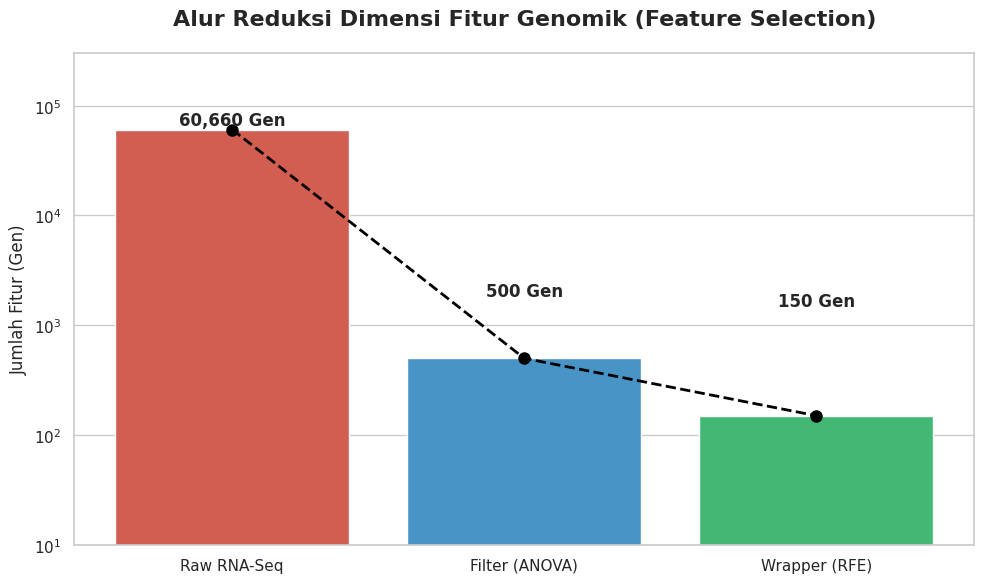

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung jumlah fitur di setiap tahap
# (Jika nama variabel Anda berbeda, sesuaikan X_scaled_df dengan nama dataframe fitur asli Anda)
jml_awal = X_scaled_df.shape[1]
jml_anova = selector_anova.get_support().sum() # Biasanya 500
jml_rfe = selector_rfe.get_support().sum()     # Biasanya 150

tahapan = ['Raw RNA-Seq', 'Filter (ANOVA)', 'Wrapper (RFE)']
jumlah = [jml_awal, jml_anova, jml_rfe]

# Mengatur gaya grafik
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Membuat Bar Plot
ax = sns.barplot(x=tahapan, y=jumlah, palette=['#e74c3c', '#3498db', '#2ecc71'])

# Menambahkan label angka di atas setiap batang
for i, v in enumerate(jumlah):
    ax.text(i, v + (jml_awal * 0.02), f"{v:,} Gen",
            ha='center', va='bottom', fontweight='bold', fontsize=12)

# Menggambar garis tren penurunan yang dramatis
plt.plot(tahapan, jumlah, color='black', marker='o', linestyle='dashed', linewidth=2, markersize=8)

plt.title('Alur Reduksi Dimensi Fitur Genomik (Feature Selection)', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Jumlah Fitur (Gen)', fontsize=12)
plt.yscale('log') # Menggunakan skala logaritmik agar batang 150 tetap terlihat proporsional
plt.ylim(10, jml_awal * 5)
plt.tight_layout()

# Tampilkan grafik
plt.show()

/tmp/ipykernel_5546/1071307054.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Importance', y='Gene_ID', data=top_10_genes, palette='viridis')


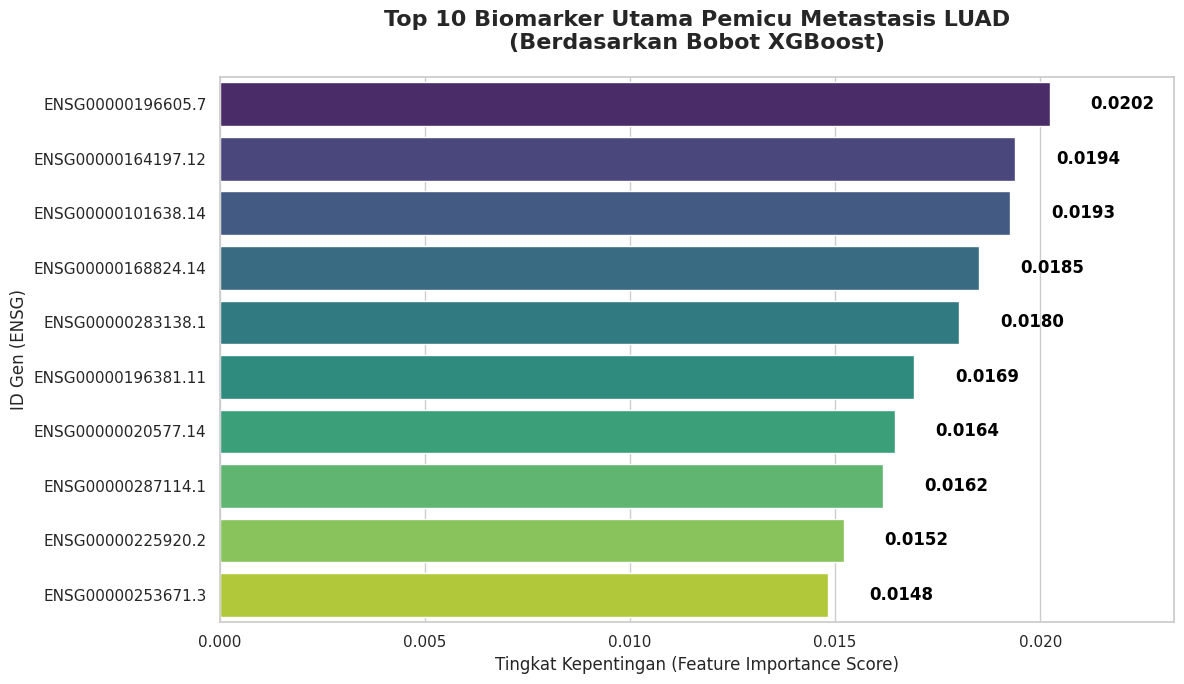

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# 0. Memuat komponen model dari file .pkl agar terjamin sama dengan aplikasi web
scaler = joblib.load('scaler_luad.pkl')
selector_anova = joblib.load('selector_anova_luad.pkl')
selector_rfe = joblib.load('selector_rfe_luad.pkl')
model = joblib.load('model_stadium_luad.pkl')

# 1. Mendapatkan nama-nama gen asli yang selamat dari seleksi ANOVA
# Mengambil nama fitur awal langsung dari scaler
fitur_awal = scaler.feature_names_in_
fitur_anova = fitur_awal[selector_anova.get_support()]

# 2. Mendapatkan nama-nama gen yang selamat dari seleksi RFE (150 Biomarker Elit)
fitur_rfe = fitur_anova[selector_rfe.get_support()]

# 3. Mengambil bobot (importance) dari XGBoost
importances = model.feature_importances_

# 4. Menggabungkan nama gen dan bobotnya ke dalam DataFrame
df_importance = pd.DataFrame({
    'Gene_ID': fitur_rfe,
    'Importance': importances
})

# 5. Mengambil Top 10 Gen dengan bobot tertinggi
top_10_genes = df_importance.sort_values(by='Importance', ascending=False).head(10)

# ==================================================
# BAGIAN VISUALISASI (PLOTTING)
# ==================================================
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

# Membuat Horizontal Bar Plot
ax = sns.barplot(x='Importance', y='Gene_ID', data=top_10_genes, palette='viridis')

# Menambahkan label nilai bobot di sebelah kanan tiap batang
for i, v in enumerate(top_10_genes['Importance']):
    ax.text(v + 0.001, i, f"{v:.4f}", color='black', va='center', fontweight='bold')

plt.title('Top 10 Biomarker Utama Pemicu Metastasis LUAD\n(Berdasarkan Bobot XGBoost)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Tingkat Kepentingan (Feature Importance Score)', fontsize=12)
plt.ylabel('ID Gen (ENSG)', fontsize=12)
plt.xlim(0, top_10_genes['Importance'].max() * 1.15) # Memberi ruang untuk teks
plt.tight_layout()

# Tampilkan grafik
plt.show()